# １章　バンディット問題
## 『ゼロから作る Deep Learning ❹』1.4〜1.6 輪読会

第 1 章の後半では、得られた報酬から各行動の価値を推定し、次の行動を選ぶ仕組みについて学ぶ。前半は勝率が変わらない環境だったが、後半では勝率が変わる環境を扱う。両者の違いを、推定値の更新式と実行結果から確かめる。

### 目次

| Section | Contents |
|---|---|
| 0. 準備・記号 | 報酬、真の価値、推定値の区別 |
| 1.4.1 | 乱数から報酬を作る仕組み |
| 1.4.2 | 標本平均の導出と配列の更新 |
| 1.4.3〜1.4.4 | 1 回の実験と多数回の平均の違い |
| 1.5.1 | 固定ステップサイズと過去の報酬の重み |
| 1.5.2 | 非定常環境での比較 |
| 1.6 | まとめ |
| Appendix | 補足資料 |

## 0. 実行環境と記号

In [2]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

# 実験ごとに乱数生成器を作る。セルを再実行しても同じ条件を再現できる。
SEED = 20261009
RUNS = 200                 # 独立にやり直す実験の数
STEPS = 1000               # 1 回の実験で行動する回数

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 60)

COLORS = ["#137C83", "#D97732", "#7455A4", "#456A9C"]
plt.rcParams.update({
    "figure.figsize": (10, 3.7), "figure.dpi": 115,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18, "font.size": 11,
    "axes.prop_cycle": matplotlib.cycler(color=COLORS),
})

print("Python", sys.version.split()[0])
print("NumPy", np.__version__, "pandas", pd.__version__,
      "Matplotlib", matplotlib.__version__)
print("本編の実験条件：", RUNS, "runs ×", STEPS, "steps")

Python 3.11.15
NumPy 1.23.5 pandas 2.3.3 Matplotlib 3.10.9
本編の実験条件： 200 runs × 1000 steps


# 1.4 バンディットアルゴリズムの実装

ここでは、バンディット問題を解くアルゴリズムを実装する。  

問題設定として、スロットマシンが返すコインが０枚か１枚の場合を考える。  
各スロットマシンには、各確率 (コインを返す確率) が設定されているとする。  
スロットは１０台あり、プレイヤーにはそれぞれの勝率が分からない中、実際にプレイした経験をもとに勝率の高いスロットマシンを探す必要がある。  

### 報酬と価値を区別する

腕 (arm) とは、選択できるスロットマシンのことである。腕が $K$ 本あるとき、Python では番号を $0,1,\ldots,K-1$ とする。エージェントはプレイヤーに相当し、環境は報酬を返す側に相当する。

| 記号 | 意味 | コード |
|---|---|---|
| $t$ | 実験全体で何回目の行動か。1 から数える | `step + 1` |
| $A_t$、$a$ | 選ぶ腕を表す確率変数と、実際に選ばれた腕番号 | `action` |
| $R_t$、$r_t$ | 報酬を表す確率変数と、得られた値 | `reward` (0 または 1) |
| $q(a)$ | 腕 $a$ の真の行動価値。エージェントは知らない | 環境の `rates[a]` |
| $Q(a)$ | 腕 $a$ の価値の推定値 | `agent.Qs[a]` |
| $N_t(a)$ | 時刻 $t$ までに腕 $a$ を選んだ回数 | `agent.ns[a]` |

$A_t$ は、乱数を使う方策では確率変数である。実行後に `action = 2` と決まったときの `2` は、その実現値である。過去の観測を固定し、決定的な規則で行動を選ぶ場合は、条件付きで選択が一意に決まる。

教科書の $Q_n$ と $R_n$ を使って平均を導出するときは、ある 1 本の腕だけに注目する。このとき $n$ は「その腕の観測回数」であり、全体の時刻 $t$ とは区別する。

## 1.4.1 スロットマシンの実装
### 勝率から報酬を作る

腕 $a$ の勝率を $p_a$ とする。得られる報酬は、当たりなら 1、外れなら 0 である。このような分布をベルヌーイ分布という。

$$
P(R_t=1\mid A_t=a)=p_a,\qquad
P(R_t=0\mid A_t=a)=1-p_a.
$$

縦棒 $\mid$ は「右側の条件のもとで」を表す。期待値は、各値にその確率を掛けて足したものである。

$$
q(a)=\mathbb{E}[R_t\mid A_t=a]
=1\times p_a+0\times(1-p_a)=p_a.
$$

この報酬設定では、真の価値と勝率が一致する。報酬が 0 と 1 以外の値を取る問題では、勝率と期待報酬は一般には一致しない。

実装には、0 以上 1 未満の一様乱数 $U$ を使う。区間 $[0,p_a)$ の長さが $p_a$ なので、$U<p_a$ となる確率は $p_a$ である。

$$
R=\begin{cases}1 & (U<p_a),\\0 & (U\ge p_a).\end{cases}
$$

,試行,一様乱数 U,U < p,報酬
0,1,0.473,True,1
1,2,0.414,True,1
2,3,0.617,False,0
3,4,0.209,True,1
4,5,0.952,False,0
5,6,0.406,True,1
6,7,0.933,False,0
7,8,0.354,True,1
8,9,0.160,True,1
9,10,0.958,False,0


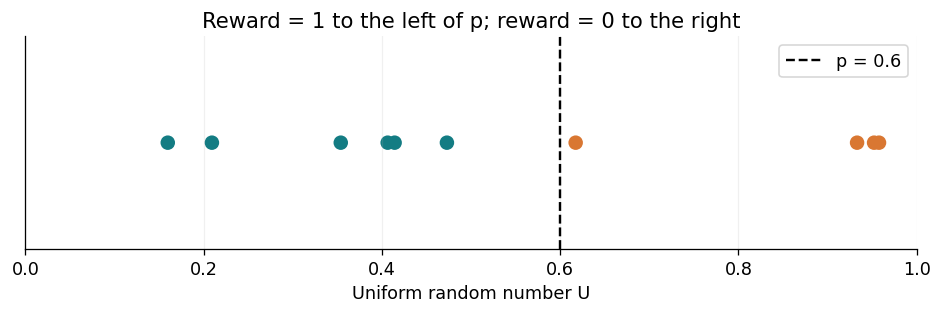

In [3]:
# 同じ腕を 10 回引いた例。p は確率であり、1 回ごとの結果ではない。
p = 0.6
rng = np.random.default_rng(SEED)
u = rng.random(10)               # shape は (10,)。各要素は 0 以上 1 未満
rewards = (u < p).astype(int)    # 真偑値を 1 と 0 に変換する
display(pd.DataFrame({"試行": np.arange(1, 11), "一様乱数 U": u,
                      "U < p": u < p, "報酬": rewards}).round(3))

fig, ax = plt.subplots(figsize=(10, 2.4))
ax.scatter(u, np.zeros(10), c=np.where(rewards == 1, COLORS[0], COLORS[1]), s=65)
ax.axvline(p, color="black", linestyle="--", label="p = 0.6")
ax.set(xlim=(0, 1), yticks=[], xlabel="Uniform random number U",
       title="Reward = 1 to the left of p; reward = 0 to the right")
ax.legend()
plt.show()

図 1：点は 10 個の乱数である。破線より左の点だけが報酬 1 になる。10 回の当たりの割合が 0.6 と一致する必要はない。確率は試行前の設定、当たりの割合は有限回の観測から計算した値である。

### 環境をクラスにまとめる

`__init__` は環境を作ったときに一度呼ばれる。`play` は腕を引くたびに呼ばれる。勝率を `__init__` で設定するので、定常環境では途中で勝率が変わらない。

教科書の `np.random.rand()` は、以下では `rng.random()` と書く。計算の意味は同じである。環境用とエージェント用の乱数生成器を分け、実験条件を再現しやすくする。

In [4]:
class Bandit:
    def __init__(self, arms=10, seed=0, rates=None):
        self.rng = np.random.default_rng(seed)
        # rates を省略したときは、腕ごとの勝率をランダムに作る。
        self.rates = (self.rng.random(arms) if rates is None
                      else np.array(rates, dtype=float, copy=True))
        if self.rates.ndim != 1 or len(self.rates) == 0:
            raise ValueError("rates は空でない 1 次元配列とする")
        if not np.all((0 <= self.rates) & (self.rates <= 1)):
            raise ValueError("勝率は 0 以上 1 以下とする")
        self.arms = len(self.rates)

    def play(self, arm):
        rate = self.rates[arm]           # 選んだ腕の勝率を 1 個取り出す
        u = self.rng.random()            # 報酬を決めるための乱数
        return int(u < rate)             # True を 1、False を 0 に変換する

bandit = Bandit(seed=SEED, rates=[0.2, 0.5, 0.8])
print("環境の勝率：", bandit.rates, "shape：", bandit.rates.shape)
print("腕 0 を 5 回選んだ報酬：", [bandit.play(0) for _ in range(5)])

環境の勝率： [0.2 0.5 0.8] shape： (3,)
腕 0 を 5 回選んだ報酬： [0, 0, 0, 0, 0]


`bandit.rates` は環境の内部情報であり、プレイヤーには見せない。後で作る `Agent` はこの配列を参照しない。エージェントが学習に使う入力は、自分が選んだ `action` と得られた `reward` だけである。

## 1.4.2 エージェントの実装
### 標本平均を 1 個ずつ更新する

ある腕を $n$ 回選び、報酬 $R_1,\ldots,R_n$ を得たとする。標本平均は、観測した値の合計を個数で割ったものである。

$$Q_n=\frac{1}{n}\sum_{i=1}^{n}R_i.$$

$\sum$ は足し合わせる記号であり、$\sum_{i=1}^{n}R_i=R_1+\cdots+R_n$ を意味する。過去の報酬を毎回足し直さなくても、前の平均 $Q_{n-1}$ があれば更新できる。$n\ge2$ のとき、

$$
\begin{aligned}
Q_n
&=\frac{R_1+\cdots+R_{n-1}+R_n}{n}\\
&=\frac{(n-1)Q_{n-1}+R_n}{n}\\
&=\frac{nQ_{n-1}-Q_{n-1}+R_n}{n}\\
&=Q_{n-1}+\frac{1}{n}(R_n-Q_{n-1}).
\end{aligned}
$$

2 行目では、過去 $n-1$ 個の合計を「個数 × 平均」に置き換えた。3 行目では $(n-1)Q_{n-1}=nQ_{n-1}-Q_{n-1}$ と展開した。教科書の式 (1.5) にあたる。

最初の観測では、任意の初期値 $Q_0$ に対して $Q_1=Q_0+(R_1-Q_0)=R_1$ となる。更新幅を表す係数 $1/n$ をステップサイズと呼ぶ。$R_n-Q_{n-1}$ は、新しい観測と今の推定値の差である。

In [5]:
# 固定した報酬列を使い、乱数に左右されず更新式を確かめる。
observed = [1, 0, 1, 1, 0]
Q = 0.0
rows = []
for n, reward in enumerate(observed, start=1):
    before = Q
    error = reward - before
    increment = error / n
    Q += increment
    direct = np.mean(observed[:n])       # 全報酬から平均を計算し直す
    rows.append([n, reward, before, error, 1 / n, increment, Q, direct])

display(pd.DataFrame(rows, columns=[
    "n", "報酬", "更新前 Q", "報酬 - Q", "1/n", "加える値", "更新後 Q", "直接の平均"
]).round(4))
np.testing.assert_allclose([r[-2] for r in rows], [r[-1] for r in rows])
print("逐次更新と直接の平均が一致した")

,n,報酬,更新前 Q,報酬 - Q,1/n,加える値,更新後 Q,直接の平均
0,1,1,0.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,0,1.0000,-1.0000,0.5000,-0.5000,0.5000,0.5000
2,3,1,0.5000,0.5000,0.3333,0.1667,0.6667,0.6667
3,4,1,0.6667,0.3333,0.2500,0.0833,0.7500,0.7500
4,5,0,0.7500,-0.7500,0.2000,-0.1500,0.6000,0.6000


逐次更新と直接の平均が一致した


2 回目は $Q_1=1$、$R_2=0$ なので、$Q_2=1+(0-1)/2=0.5$ となる。外れを観測したため、推定値を下げる。3 回目は $Q_3=0.5+(1-0.5)/3=2/3$ となる。新しい報酬をそのまま採用せず、過去の観測数に応じて更新幅を小さくしている。

標本平均の更新に必要な記憶は、腕ごとの平均と回数だけである。腕が $K$ 本なら記憶量は $O(K)$ で済み、観測回数とともに増えない。

### 探索と活用を選び分ける

$\varepsilon$-greedy 法は、確率 $\varepsilon$ で全ての腕から等確率に選び、確率 $1-\varepsilon$ で推定値が最大の腕を選ぶ。前者を探索、後者を活用と呼ぶ。`epsilon` は 0 以上 1 以下である。

活用で選ばれる腕を $a_g$ とすると、この実装の行動確率は次のようになる。

$$
P(A_t=a\mid\text{これまでの観測})=
\begin{cases}
1-\varepsilon+\varepsilon/K & (a=a_g),\\
\varepsilon/K & (a\ne a_g).
\end{cases}
$$

探索でも $a_g$ を選ぶことがある。したがって、$\varepsilon=0.1$、$K=10$ のとき、$a_g$ の選択確率は $0.9+0.01=0.91$ である。「探索した」と「最大の腕以外を選んだ」は同じ意味ではない。

In [6]:
class Agent:
    def __init__(self, epsilon=0.1, action_size=10, seed=0):
        if not 0 <= epsilon <= 1:
            raise ValueError("epsilon は 0 以上 1 以下とする")
        self.epsilon = epsilon
        self.Qs = np.zeros(action_size, dtype=float)   # 各腕の価値の推定値
        self.ns = np.zeros(action_size, dtype=int)     # 各腕を選んだ回数
        self.rng = np.random.default_rng(seed)
        self.last_explore = False                     # 説明用の記録

    def get_action(self):
        self.last_explore = self.rng.random() < self.epsilon
        if self.last_explore:
            # 上限 len(self.Qs) は含まれない。
            return int(self.rng.integers(len(self.Qs)))
        # argmax は最大値そのものではなく、その位置を返す。
        return int(np.argmax(self.Qs))

    def update(self, action, reward):
        self.ns[action] += 1                         # 今回の観測を先に数える
        self.Qs[action] += (reward - self.Qs[action]) / self.ns[action]

agent = Agent(epsilon=0.1, action_size=3, seed=SEED + 1)
print("初期 Qs：", agent.Qs, "初期 ns：", agent.ns)
print("argmax([0.2, 0.8, 0.4])：", np.argmax([0.2, 0.8, 0.4]))
print("argmax([0, 0, 0])：", np.argmax([0, 0, 0]))

初期 Qs： [0. 0. 0.] 初期 ns： [0 0 0]
argmax([0.2, 0.8, 0.4])： 1
argmax([0, 0, 0])： 0


`self` は、そのインスタンス自身を指す。例えば `agent.Qs` と `self.Qs` は、`agent` のメソッド内では同じ配列を指している。

`np.argmax` は最大値が複数あると最初の位置を返す。初期値が全て 0 の場合、活用は腕 0 を選ぶ。教科書に合わせて本編でもこの規則を使う。これは「どの腕も同じならランダムに選ぶ」という規則とは異なる。違いは付録 D で調べる。

### 1 ステップごとの中身を追う

学習の順序は「行動を選ぶ → 報酬を受け取る → その腕の回数と推定値を更新する」である。`ns[action]` を増やしてから割るので、初回の分母は 1 になる。

例えば `action = 2`、`reward = 1`、更新前が `ns[2] = 3`、`Qs[2] = 0.5` なら、回数は 4、推定値は $0.5+(1-0.5)/4=0.625$ になる。他の腕の値は変わらない。

In [7]:
bandit = Bandit(seed=SEED, rates=[0.2, 0.5, 0.8])
agent = Agent(epsilon=0.3, action_size=3, seed=SEED + 4)
trace = []
for step in range(10):
    before = agent.Qs.copy()             # 後の更新で書き換わらないよう複製する
    action = agent.get_action()
    reward = bandit.play(action)
    agent.update(action, reward)
    trace.append({
        "t": step + 1, "選択": "探索" if agent.last_explore else "活用",
        "action": action, "reward": reward,
        "更新前 Qs": np.round(before, 3).tolist(),
        "更新後 ns": agent.ns.copy().tolist(),
        "更新後 Qs": np.round(agent.Qs, 3).tolist(),
    })
display(pd.DataFrame(trace))
print("総観測回数：", agent.ns.sum(), "最後の ns：", agent.ns)

,t,選択,action,reward,更新前 Qs,更新後 ns,更新後 Qs
0,1,活用,0,0,"[0.0, 0.0, 0.0]","[1, 0, 0]","[0.0, 0.0, 0.0]"
1,2,探索,1,1,"[0.0, 0.0, 0.0]","[1, 1, 0]","[0.0, 1.0, 0.0]"
2,3,探索,2,1,"[0.0, 1.0, 0.0]","[1, 1, 1]","[0.0, 1.0, 1.0]"
3,4,活用,1,1,"[0.0, 1.0, 1.0]","[1, 2, 1]","[0.0, 1.0, 1.0]"
4,5,活用,1,0,"[0.0, 1.0, 1.0]","[1, 3, 1]","[0.0, 0.667, 1.0]"
5,6,探索,2,1,"[0.0, 0.667, 1.0]","[1, 3, 2]","[0.0, 0.667, 1.0]"
6,7,探索,0,0,"[0.0, 0.667, 1.0]","[2, 3, 2]","[0.0, 0.667, 1.0]"
7,8,活用,2,1,"[0.0, 0.667, 1.0]","[2, 3, 3]","[0.0, 0.667, 1.0]"
8,9,探索,0,1,"[0.0, 0.667, 1.0]","[3, 3, 3]","[0.333, 0.667, 1.0]"
9,10,活用,2,0,"[0.333, 0.667, 1.0]","[3, 3, 4]","[0.333, 0.667, 0.75]"


総観測回数： 10 最後の ns： [3 3 4]


表では、各行の `action` に対応する要素だけが更新される。分母は全体の時刻 `t` ではなく、その腕の `ns[action]` である。全体で 10 回行動していても、ある腕を 2 回しか選んでいなければ、その腕の更新幅は $1/2$ になる。

`copy()` は履歴の保存に必要である。配列そのものを履歴に追加すると、後で同じ配列を書き換えた際に、過去の記録まで最終状態を指すことがある。

## 1.4.3 動かしてみる
### 実験を繰り返し使える関数にする

`simulate` は、環境とエージェントを受け取り、指定した回数だけ相互作用させる。辞書として返す履歴は次のようになる。

| キー | 形状 | 入る値 |
|---|---|---|
| `actions` | `(steps,)` | 各時刻に選んだ腕番号 |
| `rewards` | `(steps,)` | 各時刻の 0/1 の報酬 |
| `total_rewards` | `(steps,)` | その時刻までの報酬の合計 |
| `rates` | `(steps,)` | その時刻までの当たりの割合 |
| `Qs` | `(steps, K)` | 各更新後の推定値 |
| `true_rates` | `(steps, K)` | 評価者が確認する、行動前の真の勝率 |

環境の `bandit.rates` と結果の `rates` は、ここでは意味が異なり、前者は各腕の設定値、後者は実際の累積報酬を回数で割った値である。

累積報酬： 901
最後の累積平均報酬： 0.901


,腕,真の勝率,推定 Q,選択回数
0,0,0.473,0.364,33
1,1,0.414,0.333,9
2,2,0.617,0.643,28
3,3,0.209,0.500,12
4,4,0.952,0.951,876
5,5,0.406,0.429,7
6,6,0.933,0.929,14
7,7,0.354,0.429,7
8,8,0.160,0.400,5
9,9,0.958,0.889,9


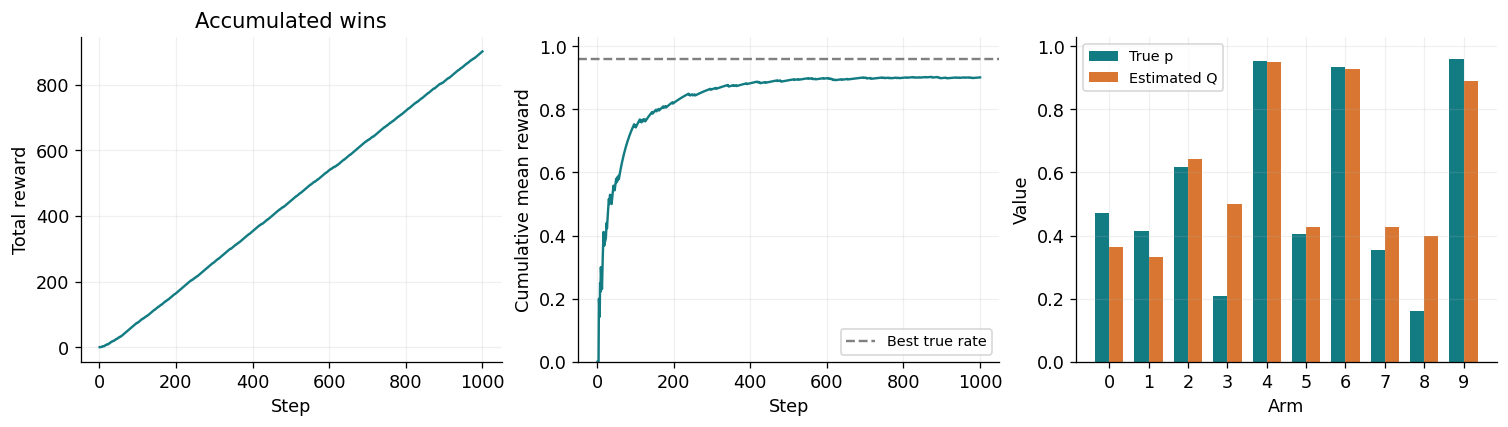

In [8]:
def simulate(bandit, agent, steps=1000):
    actions = np.empty(steps, dtype=int)
    rewards = np.empty(steps, dtype=int)
    Q_history = np.empty((steps, len(agent.Qs)))
    true_rates = np.empty_like(Q_history)
    for step in range(steps):
        # 真の勝率は評価・描画専用であり、agent には渡さない。
        true_rates[step] = np.clip(bandit.rates, 0, 1)
        action = agent.get_action()
        reward = bandit.play(action)
        agent.update(action, reward)
        actions[step], rewards[step] = action, reward
        Q_history[step] = agent.Qs      # 配列の行への代入なので値がコピーされる

    total_rewards = np.cumsum(rewards) # 例：[1, 0, 1] → [1, 1, 2]
    rates = total_rewards / np.arange(1, steps + 1)
    return dict(actions=actions, rewards=rewards, total_rewards=total_rewards,
                rates=rates, Qs=Q_history, true_rates=true_rates)

bandit = Bandit(seed=SEED)
agent = Agent(epsilon=0.1, seed=SEED + 1)
one = simulate(bandit, agent, STEPS)
print("累積報酬：", one["total_rewards"][-1])
print("最後の累積平均報酬：", round(one["rates"][-1], 3))
display(pd.DataFrame({"腕": np.arange(10), "真の勝率": bandit.rates,
                      "推定 Q": agent.Qs, "選択回数": agent.ns}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
t = np.arange(1, STEPS + 1)
axes[0].plot(t, one["total_rewards"])
axes[0].set(xlabel="Step", ylabel="Total reward", title="Accumulated wins")
axes[1].plot(t, one["rates"])
axes[1].axhline(bandit.rates.max(), color="gray", ls="--", label="Best true rate")
axes[1].set(xlabel="Step", ylabel="Cumulative mean reward", ylim=(0, 1.03))
axes[1].legend(fontsize=9)
axes[2].bar(np.arange(10) - 0.18, bandit.rates, width=0.36, label="True p")
axes[2].bar(np.arange(10) + 0.18, agent.Qs, width=0.36, label="Estimated Q")
axes[2].set(xlabel="Arm", ylabel="Value", xticks=np.arange(10), ylim=(0, 1.03))
axes[2].legend(fontsize=9)
plt.show()

図 2：左は累積報酬、中は累積平均報酬、右は真の勝率と推定値である。報酬が 0 か 1 なので、累積報酬は減らない。曲線が上がることだけでは、学習の効果は判断できない。

累積平均報酬は $\sum_{s=1}^{t}r_s/t$ であり、「今の方策で次に得る報酬の期待値」とは異なる。初期の成績も含むので、最近の変化はゆっくり反映される。中図の破線も、実現した平均値に対する絶対的な上限ではなく、最良の腕を毎回選ぶ場合の期待値の基準線である。

右図では、あまり選ばれなかった腕の推定値に大きな誤差が残ることがある。目的は、全ての腕の勝率を同じ精度で推定することではなく、限られた回数の中で多くの報酬を得ることである。

## 1.4.4 アルゴリズムの平均的な性質
### 1 回のいい結果だけで判断しない

実験結果は、各腕の初期勝率、探索で選ばれる腕、各プレイの当たり外れによって変動する。同じ条件で独立な実験を多数行い、各時刻の結果を平均する。

実験回数を $M$、実験 $j$ の報酬を $r_{j,t}$ とする。1 回の実験内の累積平均と、複数の実験間の平均は次のとおりである。

$$
C_{j,t}=\frac{1}{t}\sum_{s=1}^{t}r_{j,s},\qquad
\overline{C}_t=\frac{1}{M}\sum_{j=1}^{M}C_{j,t}.
$$

`all_rates` の行は実験、列は時刻である。`axis=0` は行方向を平均して、各時刻の値を残す。`axis=1` は各行の時刻方向を平均するため、欲しい学習曲線にならない。

In [9]:
# 配列の軸を小さな例で確認する。
example = np.array([[1.0, 0.5, 2/3], [0.0, 0.5, 1/3]])
display(pd.DataFrame(example, index=["実験 1", "実験 2"], columns=["t=1", "t=2", "t=3"]))
print("元の shape：", example.shape)
print("axis=0：", example.mean(axis=0), "shape：", example.mean(axis=0).shape)
print("axis=1：", example.mean(axis=1), "shape：", example.mean(axis=1).shape)

,t=1,t=2,t=3
実験 1,1.0,0.5,0.666667
実験 2,0.0,0.5,0.333333


元の shape： (2, 3)
axis=0： [0.5 0.5 0.5] shape： (3,)
axis=1： [0.722 0.278] shape： (2,)


### 探索率を変えて比較する

教科書と同じ $M=200$、$T=1000$ を使い、$\varepsilon=0.01,0.1,0.3$ を比べる。実験ごとに環境とエージェントを作り直すので、前の実験で学んだ推定値は持ち越さない。

比較する探索率の間では、実験番号が同じなら環境の乱数シードをそろえる。エージェントは別の乱数生成器を持つため、探索率を変えても環境の初期勝率と各時刻の報酬判定用乱数は共通になる。選んだ腕が異なれば、得られる報酬は異なり得る。

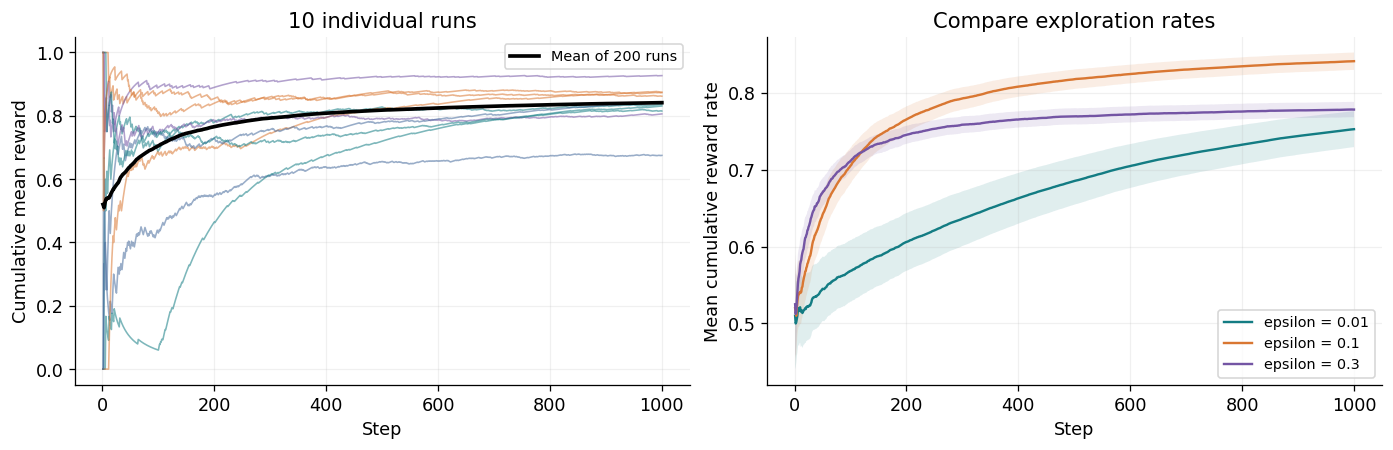

,epsilon,100 step 時点,1000 step 時点
0,0.01,0.5684,0.7529
1,0.10,0.7054,0.8415
2,0.30,0.7118,0.7785


比較実験の実行時間： 5.81 秒


In [10]:
epsilons = [0.01, 0.1, 0.3]
stationary = {}
start = time.perf_counter()
for epsilon in epsilons:
    all_rates = np.empty((RUNS, STEPS))
    for run in range(RUNS):
        env = Bandit(seed=SEED + 1000 + run)
        learner = Agent(epsilon=epsilon, seed=SEED + 10000 + run)
        history = simulate(env, learner, STEPS)
        all_rates[run] = history["rates"]
    stationary[epsilon] = all_rates

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for run in range(10):
    axes[0].plot(t, stationary[0.1][run], alpha=0.55, linewidth=1)
axes[0].plot(t, stationary[0.1].mean(axis=0), color="black", linewidth=2.3,
             label="Mean of 200 runs")
axes[0].set(xlabel="Step", ylabel="Cumulative mean reward", title="10 individual runs")
axes[0].legend(fontsize=9)
for epsilon, values in stationary.items():
    mean = values.mean(axis=0)
    sem = values.std(axis=0, ddof=1) / np.sqrt(RUNS)
    axes[1].plot(t, mean, label=f"epsilon = {epsilon}")
    axes[1].fill_between(t, mean - 1.96 * sem, mean + 1.96 * sem, alpha=0.13)
axes[1].set(xlabel="Step", ylabel="Mean cumulative reward rate", title="Compare exploration rates")
axes[1].legend(fontsize=9)
plt.show()
display(pd.DataFrame({
    "epsilon": epsilons,
    "100 step 時点": [stationary[e][:, 99].mean() for e in epsilons],
    "1000 step 時点": [stationary[e][:, -1].mean() for e in epsilons],
}).round(4))
print("比較実験の実行時間：", round(time.perf_counter() - start, 2), "秒")

図 3：左の細線は個別の実験、黒線は 200 回の平均である。右は探索率ごとの平均で、帯は各時刻における平均の近似 95% 信頼区間である。

探索率を大きくすると、早い段階で多くの腕を調べられる。ただし、良い腕が分かった後も探索を続けるため、期待報酬を下げる場合がある。探索率が小さいと、有望な腕を見つけるまで時間がかかる。どの値が良いかは、勝率の組合せと実験を打ち切る時刻にも依存する。表の 100 step 時点と 1000 step 時点を比べる。

帯の計算は、実験間の標準偏差を $s_t$ として $\overline{C}_t\pm1.96s_t/\sqrt{M}$ とした。これは独立な実験の平均に対する近似である。探索率の間では環境を共有しているため、差を詳しく検定する場合は、実験番号を対応させた差を調べる。

## 1.5 非定常問題
### 環境の変化と標本平均の遅れ

定常問題では、各腕の報酬分布が実験中に変わらない。非定常問題では、その分布が時間とともに変わる。例えば、ある腕の勝率が途中で 0.8 から 0.2 へ下がると、初期の好成績をいつまでも同じ重みで使うと変化への対応が遅れる。

標本平均では、どの報酬にも同じ重み $1/n$ が付く。

$$Q_n=\frac{1}{n}R_1+\frac{1}{n}R_2+\cdots+\frac{1}{n}R_n.$$

ある腕を 1000 回観測した後では、次の更新幅は $1/1001$ である。新しい観測が過去と大きく違っても、推定値は少ししか動かない。

## 1.5.1 非定常問題を解くために
### 固定ステップサイズで新しい観測を重くする

式 (1.5) の $1/n$ を定数 $\alpha$ に置き換える。教科書の条件は $0<\alpha<1$ である。

$$Q_n=Q_{n-1}+\alpha(R_n-Q_{n-1}).\tag{1.6}$$

$\alpha$ が大きいほど、新しい報酬によって推定値が大きく変わる。式を分配法則で整理すると、

$$
\begin{aligned}
Q_n
&=Q_{n-1}+\alpha R_n-\alpha Q_{n-1}\\
&=\alpha R_n+(1-\alpha)Q_{n-1}.
\end{aligned}
\tag{1.7}
$$

例えば $\alpha=0.2$ なら、新しい報酬を 0.2、前の推定値を 0.8 の重みで混ぜる。この 2 つの重みの和は 1 である。ただし、前の推定値にはさらに古い観測が含まれている。

### 古い報酬の重みを式で取り出す

前の推定値にも同じ更新式が成り立つ。

$$Q_{n-1}=\alpha R_{n-1}+(1-\alpha)Q_{n-2}.\tag{1.8}$$

この式を式 (1.7) の $Q_{n-1}$ に代入する。

$$
\begin{aligned}
Q_n
&=\alpha R_n+(1-\alpha)\{\alpha R_{n-1}+(1-\alpha)Q_{n-2}\}\\
&=\alpha R_n+\alpha(1-\alpha)R_{n-1}+(1-\alpha)^2Q_{n-2}.
\end{aligned}
\tag{1.9}
$$

さらに $Q_{n-2}$ を展開すると、

$$
Q_n=\alpha R_n+\alpha(1-\alpha)R_{n-1}
+\alpha(1-\alpha)^2R_{n-2}+(1-\alpha)^3Q_{n-3}.
$$

代入のたびに、まだ展開していない項へ $(1-\alpha)$ が掛かる。初期値 $Q_0$ まで戻すと、教科書の式 (1.10) になる。

$$
Q_n=\alpha R_n+\alpha(1-\alpha)R_{n-1}+\cdots
+\alpha(1-\alpha)^{n-1}R_1+(1-\alpha)^nQ_0.
\tag{1.10}
$$

同じ式を和の記号で書けば、

$$Q_n=(1-\alpha)^nQ_0+\sum_{i=1}^{n}\alpha(1-\alpha)^{n-i}R_i.$$

新しい報酬から $k$ 回前の報酬の重みは $\alpha(1-\alpha)^k$ である。$0<1-\alpha<1$ なので、古い報酬ほど重みが指数的に小さくなる。この計算を指数移動平均 (Exponential Moving Average、EMA) と呼ぶ。

### 初期値の項を省略しない

報酬だけの重みを足すと、有限の $n$ では 1 にならない。等比数列の和を使うと、

$$
\sum_{i=1}^{n}\alpha(1-\alpha)^{n-i}
=\alpha\frac{1-(1-\alpha)^n}{1-(1-\alpha)}
=1-(1-\alpha)^n.
$$

初期値の重み $(1-\alpha)^n$ を加えると 1 になる。$Q_0=0$ と設定しても、その重み自体が消えるわけではない。

例えば $\alpha=0.2$、$n=3$ なら、$R_3,R_2,R_1,Q_0$ の重みは順に $0.2,0.16,0.128,0.512$ である。初期の推定値には、初期設定が強く影響する。標本平均では初回のステップサイズが 1 なので、$Q_0$ の影響は最初の観測で消える。

In [11]:
alpha = 0.2
observed = np.array([1, 0, 1, 1, 0], dtype=float)
Q0 = 0.0
Q = Q0
rows = []
for n, reward in enumerate(observed, start=1):
    Q += alpha * (reward - Q)
    # 並びは古い報酬 R1 から新しい報酬 Rn の順である。
    weights = alpha * (1 - alpha) ** np.arange(n - 1, -1, -1)
    initial_weight = (1 - alpha) ** n
    expanded = initial_weight * Q0 + np.dot(weights, observed[:n])
    rows.append([n, reward, Q, expanded, weights.sum(), initial_weight])

display(pd.DataFrame(rows, columns=[
    "n", "報酬", "逐次更新 Q", "展開式 Q", "報酬の重みの和", "初期値の重み"
]).round(5))
np.testing.assert_allclose([r[2] for r in rows], [r[3] for r in rows])
np.testing.assert_allclose([r[4] + r[5] for r in rows], np.ones(len(rows)))
print("逐次式と展開式が一致し、初期値を含めた重みの和は 1 になった")

,n,報酬,逐次更新 Q,展開式 Q,報酬の重みの和,初期値の重み
0,1,1.0,0.20000,0.20000,0.20000,0.80000
1,2,0.0,0.16000,0.16000,0.36000,0.64000
2,3,1.0,0.32800,0.32800,0.48800,0.51200
3,4,1.0,0.46240,0.46240,0.59040,0.40960
4,5,0.0,0.36992,0.36992,0.67232,0.32768


逐次式と展開式が一致し、初期値を含めた重みの和は 1 になった


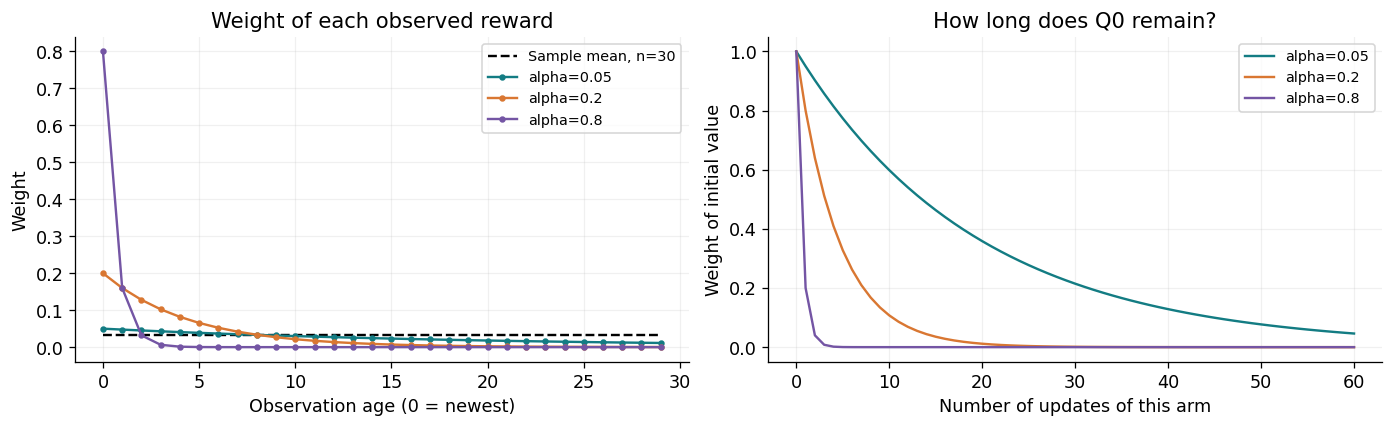

In [12]:
n = 30
age = np.arange(n)               # 0 が最新、29 が最も古い観測
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
axes[0].plot(age, np.full(n, 1 / n), color="black", ls="--", label="Sample mean, n=30")
for alpha in [0.05, 0.2, 0.8]:
    axes[0].plot(age, alpha * (1 - alpha) ** age, marker=".",
                 label=f"alpha={alpha}")
    counts = np.arange(0, 61)
    axes[1].plot(counts, (1 - alpha) ** counts, label=f"alpha={alpha}")
axes[0].set(xlabel="Observation age (0 = newest)", ylabel="Weight",
            title="Weight of each observed reward")
axes[1].set(xlabel="Number of updates of this arm", ylabel="Weight of initial value",
            title="How long does Q0 remain?")
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

図 4：左は各報酬の重み、右は初期値の重みである。$\alpha=0.8$ では直近の観測が強く反映され、過去の影響が速く小さくなる。$\alpha=0.05$ では変化が緩やかになる。

横軸は、その腕を更新した回数に基づく。選んでいない腕の `Qs` は更新されない。固定 $\alpha$ を使っていても、その腕を長時間選ばなければ、保存された推定値が自動で減衰するわけではない。

### 追従の速さと変動の大きさを分けて見る

次の実験では、1 本の腕を毎回観測し、勝率を 0.8 から 0.2 へ切り替える。行動選択を含めないことで、推定方法だけの違いを確かめる。全ての推定方法に同じ報酬列を入力する。

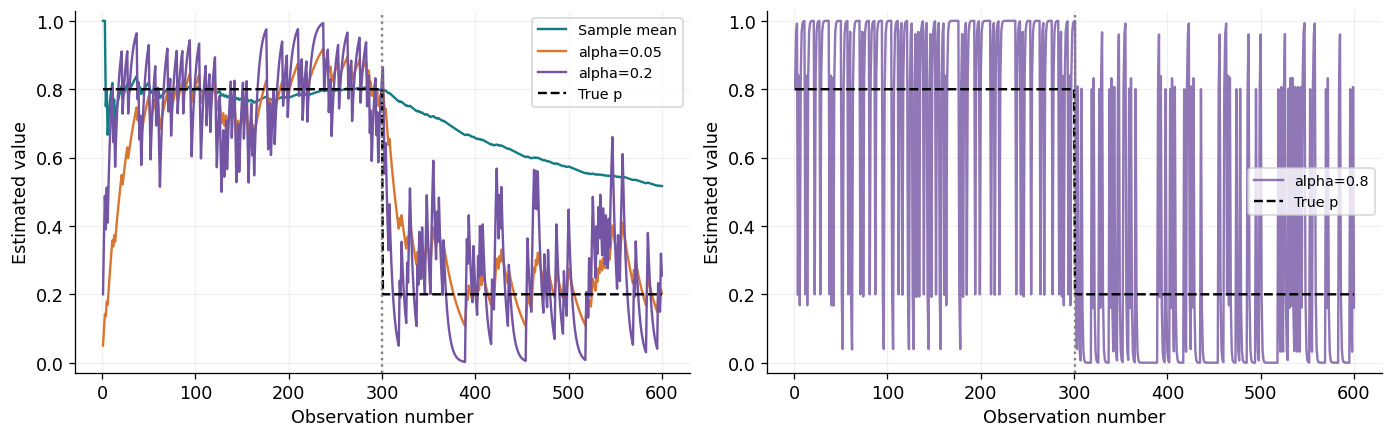

In [13]:
switch = 300
length = 600
p_path = np.r_[np.full(switch, 0.8), np.full(length - switch, 0.2)]
observed = (np.random.default_rng(SEED + 30).random(length) < p_path).astype(int)
estimates = {"Sample mean": np.cumsum(observed) / np.arange(1, length + 1)}
for alpha in [0.05, 0.2, 0.8]:
    q = 0.0
    history = []
    for reward in observed:
        q += alpha * (reward - q)
        history.append(q)
    estimates[f"alpha={alpha}"] = np.array(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), constrained_layout=True)
for name in ["Sample mean", "alpha=0.05", "alpha=0.2"]:
    axes[0].plot(np.arange(1, length + 1), estimates[name], label=name)
axes[1].plot(np.arange(1, length + 1), estimates["alpha=0.8"],
             color=COLORS[2], alpha=0.8, label="alpha=0.8")
for ax in axes:
    ax.plot(np.arange(1, length + 1), p_path, color="black", ls="--", label="True p")
    ax.axvline(switch + 0.5, color="gray", ls=":")
    ax.set(xlabel="Observation number", ylabel="Estimated value", ylim=(-0.03, 1.03))
    ax.legend(fontsize=9)
plt.show()

図 5：301 回目から真の勝率が下がる。標本平均は前半の高い報酬も同じ重みで使うため、低下への対応が遅い。固定ステップサイズなら最近の報酬が強く反映されるが、大きな $\alpha$ では 0/1 の当たり外れによる変動も大きい。

「非定常なら $\alpha$ を大きくすればよい」とは限らない。変化を速く追うことと、偶然の当たり外れを平均して抑えることの間で調整が必要になる。教科書の $\alpha=0.8$ は特定の実験条件で使った値であり、全ての問題で最適な値ではない。

## 1.5.2 非定常問題を解く
### エージェントの変更点

探索と活用の選び方はそのままにして、`update` の係数だけを $1/n$ から $\alpha$ に変える。以下では `Agent` を継承し、同じ `get_action` を使う。`ns` は比較用に記録するが、固定ステップサイズの更新式には使わない。

In [14]:
class AlphaAgent(Agent):
    def __init__(self, epsilon=0.1, alpha=0.8, action_size=10, seed=0):
        super().__init__(epsilon=epsilon, action_size=action_size, seed=seed)
        if not 0 < alpha < 1:
            raise ValueError("alpha は 0 より大きく 1 より小さくする")
        self.alpha = alpha

    def update(self, action, reward):
        self.ns[action] += 1
        self.Qs[action] += self.alpha * (reward - self.Qs[action])

### 環境が実際に返す報酬

サンプルコードの `NonStatBandit` は、各プレイで全ての腕に平均 0、標準偏差 0.1 の正規乱数を加える。`rng.standard_normal` は平均 0、標準偏差 1 の乱数を作るので、0.1 を掛けて変動幅を調整する。

$$x_{t+1,a}=x_{t,a}+0.1Z_{t,a},\qquad Z_{t,a}\sim\mathcal{N}(0,1).$$

ここで $x_{t,a}$ は、コードの `rates[a]` を厳密に説明するための補助記号である。この値には範囲制限がなく、0 未満や 1 より大きくなることがある。報酬判定が $U<x_{t,a}$ なので、実効的な勝率は次のようになる。

$$
p_{t,a}=\begin{cases}
0 & (x_{t,a}\le0),\\
x_{t,a} & (0<x_{t,a}<1),\\
1 & (x_{t,a}\ge1).
\end{cases}
$$

以下はこの挙動を保つ実装である。現在の値を `rate` に保存してから全腕を変化させ、今回の報酬には保存した値を使う。したがって、加えた変動が報酬に効くのは次のプレイからである。

In [15]:
class NonStatBandit(Bandit):
    def play(self, arm):
        rate = float(self.rates[arm])    # 今回使う、変動前の値を保存する
        self.rates += 0.1 * self.rng.standard_normal(self.arms)
        return int(self.rng.random() < rate)

# 変動前の内部値と、実際の勝率を並べて確認する。
demo_env = NonStatBandit(seed=SEED + 40)
latent_history = []
for _ in range(100):
    latent_history.append(demo_env.rates.copy())
    demo_env.play(0)                     # 選ばない腕も毎回変化する
latent_history = np.array(latent_history)
print("内部値の最小・最大：", round(latent_history.min(), 3),
      round(latent_history.max(), 3))
print("0〜1 の範囲外にある要素数：", ((latent_history < 0) | (latent_history > 1)).sum())

内部値の最小・最大： -0.616 1.849
0〜1 の範囲外にある要素数： 388


`np.clip(x, 0, 1)` は、0 未満を 0、1 より大きい値を 1 に置き換える関数である。`simulate` は実効的な勝率を記録するために `clip` を使うが、環境の内部値は変更しない。例えば内部値が 1.8 なら、その後に少し下がっても当たり確率は 1 のままになる。

毎回内部値そのものを `clip` する実装に変えると、将来の推移も変わるため、教科書とは別の環境になる。ここでは元の条件を保って比較する。「途中で最良の腕が入れ替わる環境」は付録 B を参照。

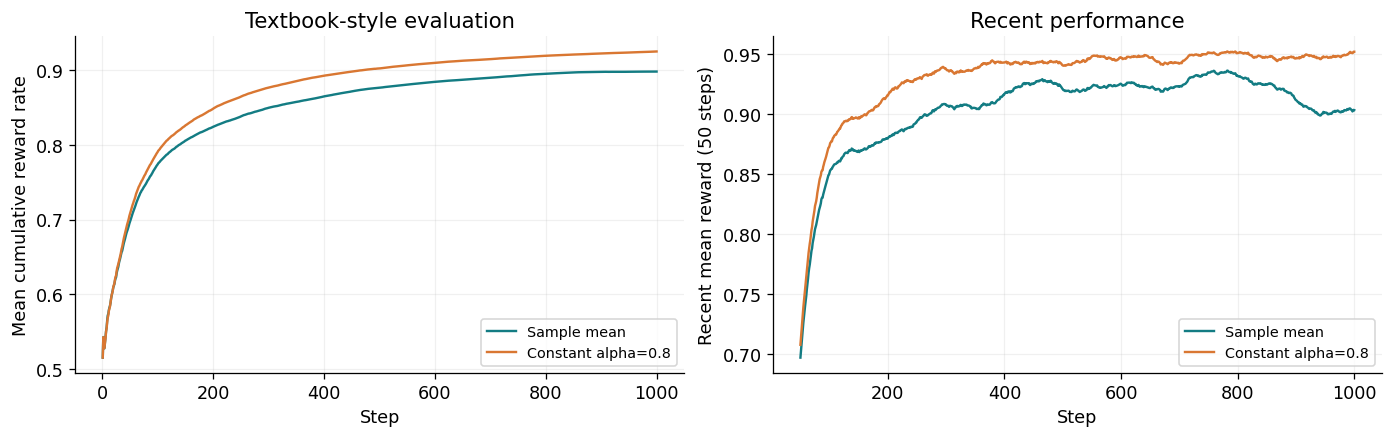

,方法,最終累積平均,最後の 200 step の平均報酬
0,Sample mean,0.8982,0.9100
1,Constant alpha=0.8,0.9251,0.9482


比較実験の実行時間： 4.46 秒


In [16]:
nonstationary = {}
start = time.perf_counter()
for method in ["Sample mean", "Constant alpha=0.8"]:
    all_rates = np.empty((RUNS, STEPS))
    all_rewards = np.empty((RUNS, STEPS))
    for run in range(RUNS):
        # 両手法で同じ環境の変動と報酬判定用乱数を共有する。
        env = NonStatBandit(seed=SEED + 20000 + run)
        learner = (Agent(epsilon=0.1, seed=SEED + 30000 + run)
                   if method == "Sample mean" else
                   AlphaAgent(epsilon=0.1, alpha=0.8, seed=SEED + 30000 + run))
        history = simulate(env, learner, STEPS)
        all_rates[run] = history["rates"]
        all_rewards[run] = history["rewards"]
    nonstationary[method] = {"rates": all_rates, "rewards": all_rewards}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), constrained_layout=True)
window = 50
for method, result in nonstationary.items():
    axes[0].plot(t, result["rates"].mean(axis=0), label=method)
    # まず同じ時刻の報酬を実験間で平均し、その後に直近 50 step を平均する。
    mean_reward = result["rewards"].mean(axis=0)
    recent = np.convolve(mean_reward, np.ones(window) / window, mode="valid")
    axes[1].plot(np.arange(window, STEPS + 1), recent, label=method)
axes[0].set(xlabel="Step", ylabel="Mean cumulative reward rate", title="Textbook-style evaluation")
axes[1].set(xlabel="Step", ylabel="Recent mean reward (50 steps)", title="Recent performance")
for ax in axes:
    ax.legend(fontsize=9)
plt.show()
display(pd.DataFrame([
    {"方法": name, "最終累積平均": d["rates"][:, -1].mean(),
     "最後の 200 step の平均報酬": d["rewards"][:, -200:].mean()}
    for name, d in nonstationary.items()
]).round(4))
print("比較実験の実行時間：", round(time.perf_counter() - start, 2), "秒")

図 6：左は教科書と同じ種類の累積平均報酬、右は最近 50 step の報酬を平均した図である。両方とも 200 回の実験を平均している。右の横軸は窓の終端なので、例えば 100 step の点は 51〜100 step の報酬を使う。

固定ステップサイズは最近の観測に反応し続ける。標本平均では観測回数が増えるほど更新幅が小さくなり、変化への対応が遅くなる。この実験の結果は、内部値が範囲外にも動く環境と探索率 0.1 に対する結果である。固定ステップサイズの優劣や最適値を、別の非定常問題にそのまま当てはめることはできない。

## 1.6 まとめ

| 観点 | 標本平均 | 固定ステップサイズ |
|---|---|---|
| 更新式 | $Q_n=Q_{n-1}+\frac{1}{n}(R_n-Q_{n-1})$ | $Q_n=Q_{n-1}+\alpha(R_n-Q_{n-1})$ |
| 過去の報酬の重み | 全て $1/n$ | 新しい報酬ほど大きい |
| 初期値の影響 | 初回の観測で消える | $(1-\alpha)^n$ の重みで残る |
| 得意な状況 | 固定した平均を多数の観測から推定する | 変化する平均を追う |
| 調整が必要な点 | 非定常環境では更新幅が小さくなりすぎる | 大きな更新幅は観測のばらつきも強く反映する |

探索率 $\varepsilon$ は「どの行動を試すか」を調整し、ステップサイズ $\alpha$ または $1/n$ は「得た報酬で推定値をどれだけ動かすか」を調整する。両者は別の役割を持つ。新しい良い腕を知るには探索が必要であり、探索で得た情報を速く反映するには更新方法の選択も必要になる。

この章のバンディットでは、選択によって次の盤面が変わるような状態遷移は扱わない。非定常環境の変化も、ここでは行動と無関係に起きる。第 2 章では、行動によって次の状態が変わる問題へ進む。

## 付録 A. 探索を続ける場合の期待報酬

最良の腕 $a^*$ を正しく見つけ、活用時には必ずその腕を選べると仮定する。定常環境での 1 回の期待報酬は、活用と探索に場合分けして求められる。

$$
\begin{aligned}
\mathbb{E}[R]
&=(1-\varepsilon)q(a^*)
+\varepsilon\left(\frac{1}{K}\sum_{a=0}^{K-1}q(a)\right)\\
&=(1-\varepsilon)q^*+\varepsilon\overline{q}.
\end{aligned}
$$

最良の腕を毎回選ぶ場合との差は $\varepsilon(q^*-\overline{q})$ である。最良の腕を知った後にも、探索には期待報酬の損失が伴う。ただし実際の学習では最良の腕を初めから知らないため、探索を省けばよいという結論にはならない。

教科書のように $K$ 本の真の勝率を独立な一様分布から作る場合、最大値を $X$ とすると、全ての勝率が $x$ 以下になる確率は $P(X\le x)=x^K$ である。密度は $Kx^{K-1}$ なので、

$$\mathbb{E}[X]=\int_0^1 x\cdot Kx^{K-1}\,dx=\frac{K}{K+1}.$$

各腕の勝率の平均の期待値は $1/2$ である。したがって、最良の腕を既知とした $\varepsilon$-greedy 法の平均的な期待報酬は、$K=10$、$\varepsilon=0.1$ なら $0.9\times10/11+0.1\times1/2\simeq0.8682$ になる。これは学習初期の損失を含む有限回の実験結果が必ず到達する値ではない。

In [17]:
K = 10
display(pd.DataFrame({
    "epsilon": [0.01, 0.1, 0.3],
    "最良腕が既知の場合の期待報酬": [
        (1 - e) * K / (K + 1) + e * 0.5 for e in [0.01, 0.1, 0.3]
    ],
}).round(4))

,epsilon,最良腕が既知の場合の期待報酬
0,0.01,0.9050
1,0.10,0.8682
2,0.30,0.7864


## 付録 B. 最良の腕が途中で入れ替わる実験

4 本の腕を用意する。最初の 400 step は勝率を `[0.8, 0.2, 0.4, 0.3]` とし、401 step 目から `[0.2, 0.8, 0.4, 0.3]` に切り替える。勝率が既知の時刻に変わるため、探索と追従の遅れを読み取りやすい。教科書のランダムウォークとは別の追加実験である。

評価には累積擬リグレットも使う。擬リグレットは、各時刻の最良の期待報酬と、実際に選んだ腕の期待報酬の差を足したものである。

$$\mathcal{L}_T=\sum_{t=1}^{T}\left(\max_a p_{t,a}-p_{t,A_t}\right).$$

これは観測した 0/1 の報酬差ではない。シミュレーターの真の勝率を使う評価量であり、エージェントは計算に使わない。小さいほど、その時々の良い腕を選べている。

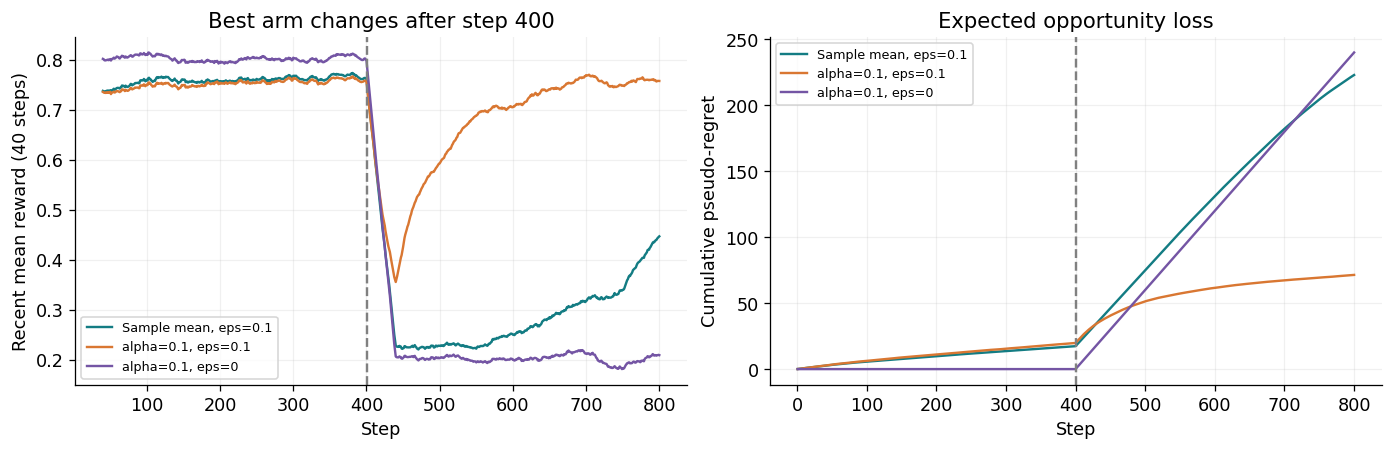

In [18]:
class SwitchingBandit(Bandit):
    def __init__(self, seed=0, switch_at=400):
        super().__init__(seed=seed, rates=[0.8, 0.2, 0.4, 0.3])
        self.after = np.array([0.2, 0.8, 0.4, 0.3])
        self.switch_at = switch_at
        self.calls = 0

    def play(self, arm):
        reward = super().play(arm)   # 今回の勝率で報酬を生成する
        self.calls += 1
        if self.calls == self.switch_at:
            self.rates = self.after.copy()  # 次のプレイから新しい勝率を使う
        return reward

switch_steps, switch_runs, switch_at = 800, 120, 400
switch_results = {}
for name, epsilon, alpha in [
    ("Sample mean, eps=0.1", 0.1, None),
    ("alpha=0.1, eps=0.1", 0.1, 0.1),
    ("alpha=0.1, eps=0", 0.0, 0.1),
]:
    collected_rewards, collected_regret = [], []
    for run in range(switch_runs):
        env = SwitchingBandit(seed=SEED + 40000 + run, switch_at=switch_at)
        learner = (Agent(epsilon, action_size=4, seed=SEED + 50000 + run)
                   if alpha is None else
                   AlphaAgent(epsilon, alpha, action_size=4, seed=SEED + 50000 + run))
        h = simulate(env, learner, switch_steps)
        chosen_p = h["true_rates"][np.arange(switch_steps), h["actions"]]
        gaps = h["true_rates"].max(axis=1) - chosen_p
        collected_rewards.append(h["rewards"])
        collected_regret.append(np.cumsum(gaps))
    switch_results[name] = (np.array(collected_rewards), np.array(collected_regret))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for name, (reward_array, regret_array) in switch_results.items():
    recent = np.convolve(reward_array.mean(axis=0), np.ones(40) / 40, mode="valid")
    axes[0].plot(np.arange(40, switch_steps + 1), recent, label=name)
    axes[1].plot(np.arange(1, switch_steps + 1), regret_array.mean(axis=0), label=name)
for ax in axes:
    ax.axvline(switch_at + 0.5, color="gray", ls="--")
    ax.set_xlabel("Step")
    ax.legend(fontsize=8)
axes[0].set(ylabel="Recent mean reward (40 steps)", title="Best arm changes after step 400")
axes[1].set(ylabel="Cumulative pseudo-regret", title="Expected opportunity loss")
plt.show()

図 7：破線の後は腕 1 が最良になる。固定幅と探索を組み合わせた場合に、成績がどう回復するかを確認する。探索なしの実装では、腕 0 の推定値は報酬 0 の更新で減るが、有限回の更新では正のままである。他の腕は未観測の 0 なので、この設定では腕 0 を選び続ける。更新幅を変えるだけでは、未知の腕の情報は得られない。

この実験では全ての手法で、環境の変化と報酬判定用乱数を実験番号ごとに共有した。環境を有利なものへ入れ替えて比較しているわけではない。

## 付録 C. 重みの半減回数と有効観測数

古い観測の重みが半分になるまでの更新回数を $h$ とすると、$(1-\alpha)^h=1/2$ である。両辺の対数を取ると、

$$h=\frac{\log(1/2)}{\log(1-\alpha)}.$$

これは重みの半減に対応する実数値であり、全体の経過 step 数ではない。$\alpha=0.1$ なら約 6.58 回、その腕を更新する間に重みが半分になる。

定常な 1 本の腕を固定回数だけ観測する場合の分散も調べられる。報酬が独立で平均 $p$、分散 $\sigma^2=p(1-p)$ とする。初期値の影響が十分小さくなった後は、

$$
\begin{aligned}
\operatorname{Var}(Q)
&=\sigma^2\sum_{k=0}^{\infty}\{\alpha(1-\alpha)^k\}^2\\
&=\sigma^2\frac{\alpha^2}{1-(1-\alpha)^2}
=\sigma^2\frac{\alpha}{2-\alpha}.
\end{aligned}
$$

独立な報酬の加重和では、各分散に重みの 2 乗を掛けて足す。標本平均の分散 $\sigma^2/n$ と形式的に比較すると、有効な観測数は $(2-\alpha)/\alpha$ 程度になる。この値と半減回数は異なる尺度である。また、この分散式は独立・定常な報酬を前提とし、非定常な値の追跡や、適応的に選んだ腕の評価にそのまま適用しない。

In [19]:
alphas = np.array([0.01, 0.05, 0.1, 0.2, 0.8])
display(pd.DataFrame({
    "alpha": alphas,
    "重みの半減回数": np.log(0.5) / np.log(1 - alphas),
    "分散から見た有効観測数": (2 - alphas) / alphas,
}).round(3))

,alpha,重みの半減回数,分散から見た有効観測数
0,0.01,68.968,199.0
1,0.05,13.513,39.0
2,0.10,6.579,19.0
3,0.20,3.106,9.0
4,0.80,0.431,1.5


## 付録 D. 同率最大の腕の選び方

教科書の `argmax` は、同率最大の最初の腕を選ぶ。初期状態で全ての推定値が 0 のとき、$\varepsilon=0.1$、$K=4$ なら、腕 0 は確率 0.925、他の腕はそれぞれ確率 0.025 で選ばれる。

活用時にも同率最大の候補から等確率に選ぶ実装なら、初期状態では全ての腕が確率 0.25 で選ばれる。次の実験では推定値を更新せず、行動選択規則だけを比較する。

In [20]:
class RandomTieAgent(Agent):
    def get_action(self):
        self.last_explore = self.rng.random() < self.epsilon
        if self.last_explore:
            return int(self.rng.integers(len(self.Qs)))
        candidates = np.flatnonzero(self.Qs == self.Qs.max())
        return int(self.rng.choice(candidates))

first = Agent(epsilon=0.1, action_size=4, seed=SEED + 70)
random_tie = RandomTieAgent(epsilon=0.1, action_size=4, seed=SEED + 71)
draws = 20000
freq_first = np.bincount([first.get_action() for _ in range(draws)], minlength=4) / draws
freq_random = np.bincount([random_tie.get_action() for _ in range(draws)], minlength=4) / draws
display(pd.DataFrame({"腕": np.arange(4), "先頭を選ぶ規則": freq_first,
                      "同率からランダムに選ぶ規則": freq_random}).round(4))

,腕,先頭を選ぶ規則,同率からランダムに選ぶ規則
0,0,0.9268,0.2492
1,1,0.0242,0.2560
2,2,0.0240,0.2449
3,3,0.0250,0.2499
